In [1]:
import pandas as pd

data = {
    'review': [
        # Positive - 20
        'I love this product, it works perfectly',
        'Amazing quality, highly recommended',
        'Best purchase ever, I am very happy',
        'Excellent service and fast delivery',
        'Great value for money, will buy again',
        'I really enjoyed using this, fantastic',
        'Superb experience, exceeded my expectations',
        'Very good product, I am satisfied',
        'Wonderful, works exactly as described',
        'I love it, the quality is amazing',
        'Perfect, exactly what I needed',
        'Great product, easy to use and reliable',
        'Highly satisfied, best quality so far',
        'Awesome, I will recommend to my friends',
        'Beautiful design and works great',
        'Fantastic customer service, very helpful',
        'I am happy with this purchase',
        'Excellent, worth every penny',
        'Good quality and fast shipping',
        'This is amazing, I love it so much',
        # Negative - 20
        'I hate this product, it is terrible',
        'Worst purchase ever, very disappointed',
        'Bad quality, broke after one day',
        'Terrible service, I will never buy again',
        'Very poor quality, waste of money',
        'I am disappointed, it does not work',
        'Horrible experience, completely useless',
        'Bad product, not worth the price',
        'I regret buying this, awful',
        'Poor delivery and damaged product',
        'This is the worst, I hate it',
        'Useless product, stopped working quickly',
        'Terrible quality, I want a refund',
        'Very bad, I am not happy at all',
        'Disappointing, does not work as promised',
        'Awful service, rude and slow',
        'I do not like this at all',
        'Broken on arrival, very frustrating',
        'Waste of time and money',
        'Bad experience, will not recommend',
        # Neutral - 20
        'The product is okay, nothing special',
        'It works, but not great',
        'Average quality, average price',
        'Delivery was okay, product is fine',
        'It is alright, I have no strong feelings',
        'The product is as expected',
        'Not bad, not good, just okay',
        'It does the job, nothing more',
        'Average experience, could be better',
        'The product is fine for the price',
        'It is usable, but not impressive',
        'Okay product, meets basic needs',
        'Neither good nor bad',
        'It is decent, nothing to complain about',
        'Normal product, normal quality',
        'It works as described, nothing special',
        'Fair enough, average performance',
        'The service was okay',
        'It is acceptable, not amazing',
        'Just average, I am neutral about it'
    ],
    'sentiment': ['positive']*20 + ['negative']*20 + ['neutral']*20
}

df = pd.DataFrame(data)
print(df.shape)
print(df['sentiment'].value_counts())
print(df.head())

(60, 2)
sentiment
positive    20
negative    20
neutral     20
Name: count, dtype: int64
                                    review sentiment
0  I love this product, it works perfectly  positive
1      Amazing quality, highly recommended  positive
2      Best purchase ever, I am very happy  positive
3      Excellent service and fast delivery  positive
4    Great value for money, will buy again  positive


In [2]:
import re
import nltk
from nltk.corpus import stopwords

nltk.download('stopwords')
stop_words = set(stopwords.words('english'))

def clean_text(text):
    text = text.lower()  # lowercase
    text = re.sub(r'[^a-z\s]', '', text)  # remove punctuation / numbers
    words = text.split()  # tokenization
    words = [w for w in words if w not in stop_words]  # remove stopwords
    return ' '.join(words)

df['clean_review'] = df['review'].apply(clean_text)

print(df[['review', 'clean_review']].head(10))

                                        review  \
0      I love this product, it works perfectly   
1          Amazing quality, highly recommended   
2          Best purchase ever, I am very happy   
3          Excellent service and fast delivery   
4        Great value for money, will buy again   
5       I really enjoyed using this, fantastic   
6  Superb experience, exceeded my expectations   
7            Very good product, I am satisfied   
8        Wonderful, works exactly as described   
9            I love it, the quality is amazing   

                              clean_review  
0             love product works perfectly  
1       amazing quality highly recommended  
2                 best purchase ever happy  
3          excellent service fast delivery  
4                    great value money buy  
5           really enjoyed using fantastic  
6  superb experience exceeded expectations  
7                   good product satisfied  
8        wonderful works exactly described  

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [3]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# TF-IDF - turn text into numbers
vectorizer = TfidfVectorizer()
X = vectorizer.fit_transform(df['clean_review'])
y = df['sentiment']

# 80% train / 20% test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)

# Model 1 - Naive Bayes
nb = MultinomialNB()
nb.fit(X_train, y_train)
nb_pred = nb.predict(X_test)

# Model 2 - Logistic Regression
lr = LogisticRegression(max_iter=1000)
lr.fit(X_train, y_train)
lr_pred = lr.predict(X_test)

print("\n--- Naive Bayes Accuracy:", accuracy_score(y_test, nb_pred))
print(classification_report(y_test, nb_pred))

print("\n--- Logistic Regression Accuracy:", accuracy_score(y_test, lr_pred))
print(classification_report(y_test, lr_pred))

print("\nNaive Bayes Confusion Matrix:\n", confusion_matrix(y_test, nb_pred))
print("\nLogistic Regression Confusion Matrix:\n", confusion_matrix(y_test, lr_pred))

Train shape: (48, 111)
Test shape: (12, 111)

--- Naive Bayes Accuracy: 0.6666666666666666
              precision    recall  f1-score   support

    negative       0.33      1.00      0.50         2
     neutral       1.00      0.50      0.67         6
    positive       1.00      0.75      0.86         4

    accuracy                           0.67        12
   macro avg       0.78      0.75      0.67        12
weighted avg       0.89      0.67      0.70        12


--- Logistic Regression Accuracy: 0.6666666666666666
              precision    recall  f1-score   support

    negative       0.33      1.00      0.50         2
     neutral       1.00      0.50      0.67         6
    positive       1.00      0.75      0.86         4

    accuracy                           0.67        12
   macro avg       0.78      0.75      0.67        12
weighted avg       0.89      0.67      0.70        12


Naive Bayes Confusion Matrix:
 [[2 0 0]
 [3 3 0]
 [1 0 3]]

Logistic Regression Confusion Ma

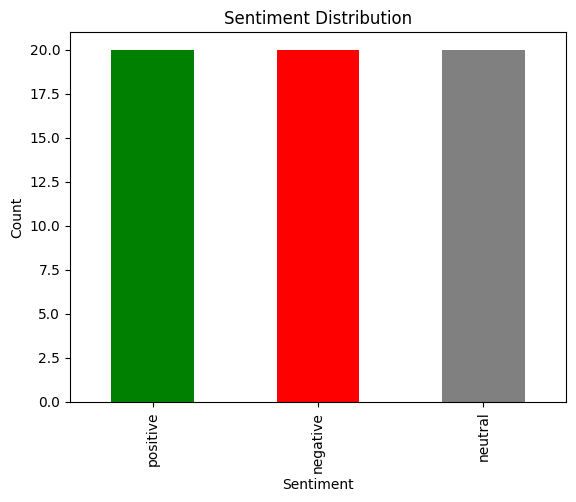

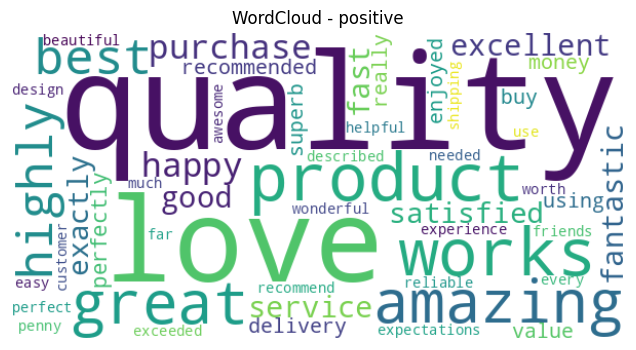

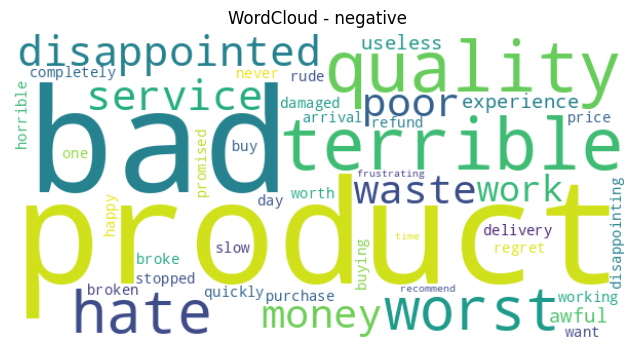

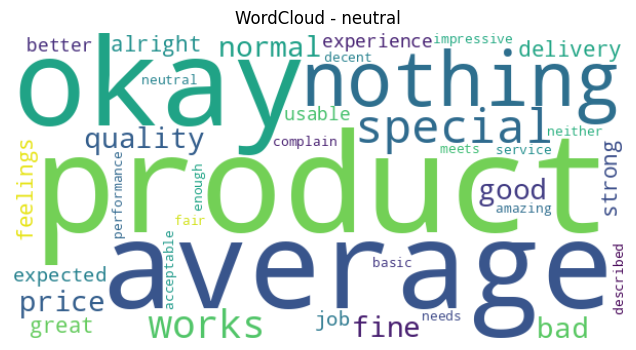

Errors found: 4
                                     review    actual predicted
45               The product is as expected   neutral  negative
13  Awesome, I will recommend to my friends  positive  negative
54           Normal product, normal quality   neutral  negative
50         It is usable, but not impressive   neutral  negative


In [4]:
import matplotlib.pyplot as plt
from wordcloud import WordCloud

# 1. Bar chart - Sentiment distribution
df['sentiment'].value_counts().plot(kind='bar', color=['green', 'red', 'gray'])
plt.title('Sentiment Distribution')
plt.xlabel('Sentiment')
plt.ylabel('Count')
plt.show()

# 2. WordCloud for each sentiment
for sentiment in ['positive', 'negative', 'neutral']:
    text = ' '.join(df[df['sentiment']==sentiment]['clean_review'])
    wc = WordCloud(width=600, height=300, background_color='white').generate(text)
    plt.figure(figsize=(8,4))
    plt.imshow(wc, interpolation='bilinear')
    plt.axis('off')
    plt.title(f'WordCloud - {sentiment}')
    plt.show()

# 3. Error Analysis - 5 examples model got wrong (using Logistic Regression)
import pandas as pd
test_df = pd.DataFrame({'review': df.iloc[y_test.index]['review'], 'actual': y_test, 'predicted': lr_pred})
errors = test_df[test_df['actual'] != test_df['predicted']]
print("Errors found:", len(errors))
print(errors.head(5))

## Conclusion

Both Naive Bayes and Logistic Regression achieved 67% accuracy on the test set, so they performed equally on this small dataset.

The confusion matrices show the main errors were Neutral and Positive reviews being predicted as Negative. This happens because words like "product" and "quality" appear in all sentiments, and with only 60 reviews, the models do not have enough examples to separate Neutral from Negative clearly.

With a larger dataset like IMDB or Amazon reviews, Logistic Regression would usually perform slightly better because it learns word weights better, while Naive Bayes is faster and works well as a baseline.

Real-world use: Companies use sentiment analysis to automatically read thousands of customer reviews, tweets, and feedback, to know if customers are happy, angry, or neutral, without reading each one manually.